# 📊 Phân tích Sơ bộ Bộ Dữ liệu 100 Mẫu Cân Bằng — LarkAssistant

**Mục tiêu:** Khám phá và kiểm tra độ cân bằng của bộ dữ liệu huấn luyện 100 mẫu cho LarkAssistant.  
Bộ dữ liệu gồm các tin nhắn giả lập được gán nhãn thủ công theo hai quyết định: **Có cần trả lời?** và **Có cần ghi nhớ?**

---
**File:** `bo_du_lieu_100_can_bang.xlsx`  
**Các tab phân tích:**
- `Dữ liệu 100` — dữ liệu chính (100 dòng × 29 cột)
- `Hướng dẫn` — metadata mô tả các cột
- `Danh sách` — danh sách giá trị hợp lệ

## 0. Setup & Import thư viện

In [1]:
# --- Cài đặt thư viện (chạy lần đầu) ---
#!uv pip install pandas openpyxl matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='muted')

FILE_PATH = 'bo_du_lieu_100_can_bang.xlsx'
print('Setup hoan tat.')

Setup hoan tat.


---
## 1. Metadata tu Tab Huong dan

Tab `Huong dan` chua mo ta chi tiet cho tung cot trong bo du lieu.

In [2]:
df_meta = pd.read_excel(FILE_PATH, sheet_name='Hướng dẫn')
df_meta.columns = ['Cot', 'Y nghia', 'Ai dien', 'Vi du']
print(f'So cot duoc mo ta: {len(df_meta)}')
display(df_meta)

So cot duoc mo ta: 29


,Cot,Y nghia,Ai dien,Vi du
0,ID,Mã duy nhất của tin nhắn,Hệ thống,MSG001
1,Tin nhắn,Nội dung tin gửi lãnh đạo,Dữ liệu gốc,Anh duyệt giúp em phương án này nhé.
2,Kênh,Tin nhắn riêng hay nhóm,Dữ liệu gốc,DM / GROUP
3,Mã thread,Mã cuộc hội thoại giả lập,Dữ liệu gốc,TH001
4,Người gửi,Tên người gửi giả lập,Dữ liệu gốc,Lan
5,Vai trò,Vai trò công việc giả lập,Dữ liệu gốc,Quản lý dự án
6,Nhóm / phạm vi,Nhóm hoặc phạm vi thông tin,Dữ liệu gốc,Dự án Nova
7,Dự án,Dự án / phạm vi công việc,Dữ liệu gốc,Dự án Nova
8,Thời gian,Thời điểm nhận tin,Dữ liệu gốc,2026-10-05 08:12
9,Có file?,Có tài liệu đính kèm không,Dữ liệu gốc,Có


In [3]:
print('Phan nhom cot theo Ai dien:')
for group, grp_df in df_meta.groupby('Ai dien'):
    cols = ', '.join(grp_df['Cot'].tolist())
    print(f'\n[{group}] ({len(grp_df)} cot):\n  {cols}')

Phan nhom cot theo Ai dien:

[Dữ liệu gốc] (12 cot):
  Tin nhắn, Kênh, Mã thread, Người gửi, Vai trò, Nhóm / phạm vi, Dự án, Thời gian, Có file?, Tên file, Nhắc lãnh đạo?, Loại tin

[Hệ thống] (5 cot):
  ID, Kết quả model trả lời, Độ tin cậy trả lời, Kết quả model ghi nhớ, Độ tin cậy ghi nhớ

[Nhãn] (9 cot):
  Có cần trả lời?, Cách xử lý, Có cần ghi nhớ?, Loại thông tin nhớ, Mức rủi ro, Thiếu context?, Lý do gán nhãn, Ứng viên regex?, Mã pattern

[Review] (2 cot):
  Review cuối, Ghi chú

[Đã gán nhãn] (1 cot):
  Nhóm nhãn


### Danh sach gia tri hop le (tab Danh sach)

In [4]:
df_ds = pd.read_excel(FILE_PATH, sheet_name='Danh sách', header=None)
print('Cac gia tri hop le theo tung nhom:\n')
for _, row in df_ds.iterrows():
    vals = [str(v) for v in row[1:] if pd.notna(v)]
    print(f'{row[0]}: {", ".join(vals)}')

Cac gia tri hop le theo tung nhom:

Nhóm nhãn: A - Trả lời + Ghi nhớ, B - Trả lời + Không ghi nhớ, C - Không trả lời + Ghi nhớ, D - Không trả lời + Không ghi nhớ
Có cần trả lời?: Có, Không
Có cần ghi nhớ?: Có, Không
Cách xử lý: Soạn nháp, Hỏi lại, Bỏ qua, Tự trả lời
Mức rủi ro: Thấp, Trung bình, Cao
Mã pattern: M01 - Duyệt/Xác nhận, M02 - Hỏi/Xin ý kiến, M03 - Cập nhật trạng thái, M04 - Lịch/Deadline
Mã pattern: M05 - Nội dung nhạy cảm


---
## 2. Nap du lieu chinh (Tab Du lieu 100)

In [5]:
df = pd.read_excel(FILE_PATH, sheet_name='Dữ liệu 100')
print(f'Kich thuoc: {df.shape[0]} dong x {df.shape[1]} cot')
print(f'\nCac cot: {list(df.columns)}')

Kich thuoc: 100 dong x 29 cot

Cac cot: ['ID', 'Tin nhắn', 'Kênh', 'Mã thread', 'Người gửi', 'Vai trò', 'Nhóm / phạm vi', 'Dự án', 'Thời gian', 'Có file?', 'Tên file', 'Nhắc lãnh đạo?', 'Loại tin', 'Nhóm nhãn', 'Có cần trả lời?', 'Cách xử lý', 'Có cần ghi nhớ?', 'Loại thông tin nhớ', 'Mức rủi ro', 'Thiếu context?', 'Lý do gán nhãn', 'Ứng viên regex?', 'Mã pattern', 'Kết quả model trả lời', 'Độ tin cậy trả lời', 'Kết quả model ghi nhớ', 'Độ tin cậy ghi nhớ', 'Review cuối', 'Ghi chú']


In [6]:
df.head(5)

,ID,Tin nhắn,Kênh,Mã thread,Người gửi,Vai trò,Nhóm / phạm vi,Dự án,Thời gian,Có file?,...,Thiếu context?,Lý do gán nhãn,Ứng viên regex?,Mã pattern,Kết quả model trả lời,Độ tin cậy trả lời,Kết quả model ghi nhớ,Độ tin cậy ghi nhớ,Review cuối,Ghi chú
0,MSG001,Vậy chốt theo đó nha anh?,GROUP,TH001,Mai,Marketing,Dự án Nova,Dự án Nova,2026-10-05 08:12,Không,...,Có,"Thiếu thread trước nên không rõ ""đó"" là gì; ch...",Không,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MSG002,Anh chốt giá như em nói hôm qua nhé.,DM,TH002,Huyền,Kinh doanh,Dự án Atlas,Dự án Atlas,2026-10-05 08:17,Không,...,Có,Cần hỏi lại vì không nêu mức giá cụ thể; chốt ...,Có,M05,NaN,NaN,NaN,NaN,NaN,NaN
2,MSG003,Cho em hỏi địa chỉ văn phòng bên khách để em đ...,DM,TH003,Nam,Kinh doanh,Dự án Atlas,Dự án Atlas,2026-10-05 08:28,Không,...,Không,Địa chỉ khách đã lưu sẵn; trợ lý trả lời được.,Không,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MSG004,"Dạ đối tác xác nhận họp 14h thứ Năm, link họp ...",GROUP,TH004,Nam,Kinh doanh,Dự án Atlas,Dự án Atlas,2026-10-05 08:33,Không,...,Không,Link họp có sẵn trong lịch; trợ lý gửi lại đượ...,Có,M04,NaN,NaN,NaN,NaN,NaN,NaN
4,MSG005,"Dạ demo dời sang 15/10 rồi phải không ạ, em bá...",GROUP,TH005,Minh,Kỹ thuật,Dự án Nova,Dự án Nova,2026-10-05 08:40,Không,...,Không,Lịch demo đã cập nhật (15/10); trợ lý xác nhận...,Có,M04,NaN,NaN,NaN,NaN,NaN,NaN


### 2.1 Kieu du lieu & Gia tri null

In [7]:
summary = pd.DataFrame({
    'Kieu du lieu': df.dtypes,
    'Khong null': df.notna().sum(),
    'So null': df.isna().sum(),
    '% null': (df.isna().mean() * 100).round(1),
    'Duy nhat': df.nunique()
})
display(summary)

,Kieu du lieu,Khong null,So null,% null,Duy nhat
ID,str,100,0,0.0,100
Tin nhắn,str,100,0,0.0,100
Kênh,str,100,0,0.0,2
Mã thread,str,100,0,0.0,100
Người gửi,str,100,0,0.0,10
Vai trò,str,100,0,0.0,8
Nhóm / phạm vi,str,100,0,0.0,3
Dự án,str,100,0,0.0,3
Thời gian,str,100,0,0.0,100
Có file?,str,100,0,0.0,2


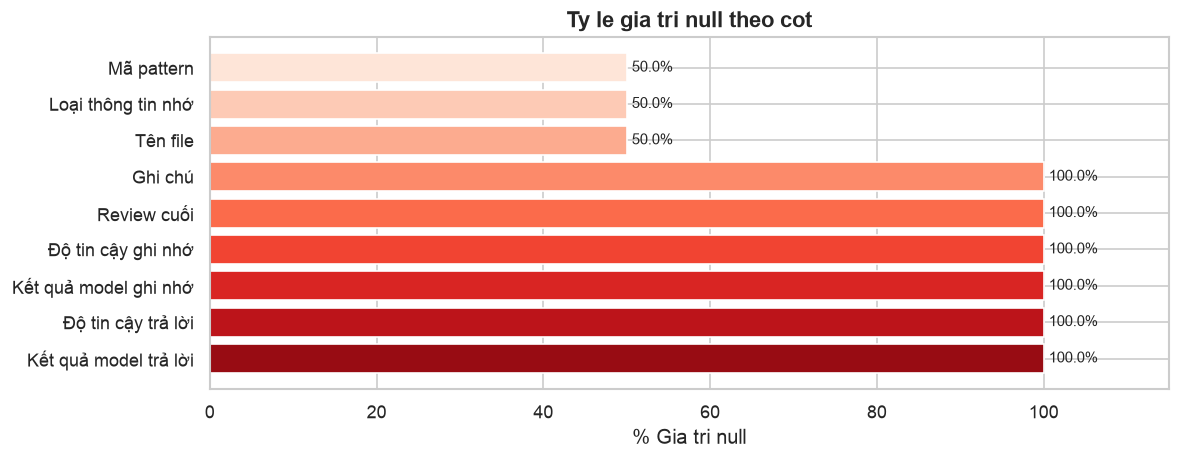

Note: Cac cot model/review de trong la binh thuong - du lieu chua qua chay model.


In [8]:
null_pct = df.isna().mean() * 100
null_pct = null_pct[null_pct > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(null_pct.index, null_pct.values, color=sns.color_palette('Reds_r', len(null_pct)))
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_xlabel('% Gia tri null')
ax.set_title('Ty le gia tri null theo cot', fontweight='bold', fontsize=13)
ax.set_xlim(0, 115)
plt.tight_layout()
plt.show()
print('Note: Cac cot model/review de trong la binh thuong - du lieu chua qua chay model.')

---
## 3. Kiem tra Do Can Bang Nhan Chinh

### 3.1 Phan phoi Nhom nhan (4 to hop A/B/C/D)

,So luong,Ty le (%)
Nhóm nhãn,,
A - Trả lời + Ghi nhớ,25,25.0
D - Không trả lời + Không ghi nhớ,25,25.0
C - Không trả lời + Ghi nhớ,25,25.0
B - Trả lời + Không ghi nhớ,25,25.0


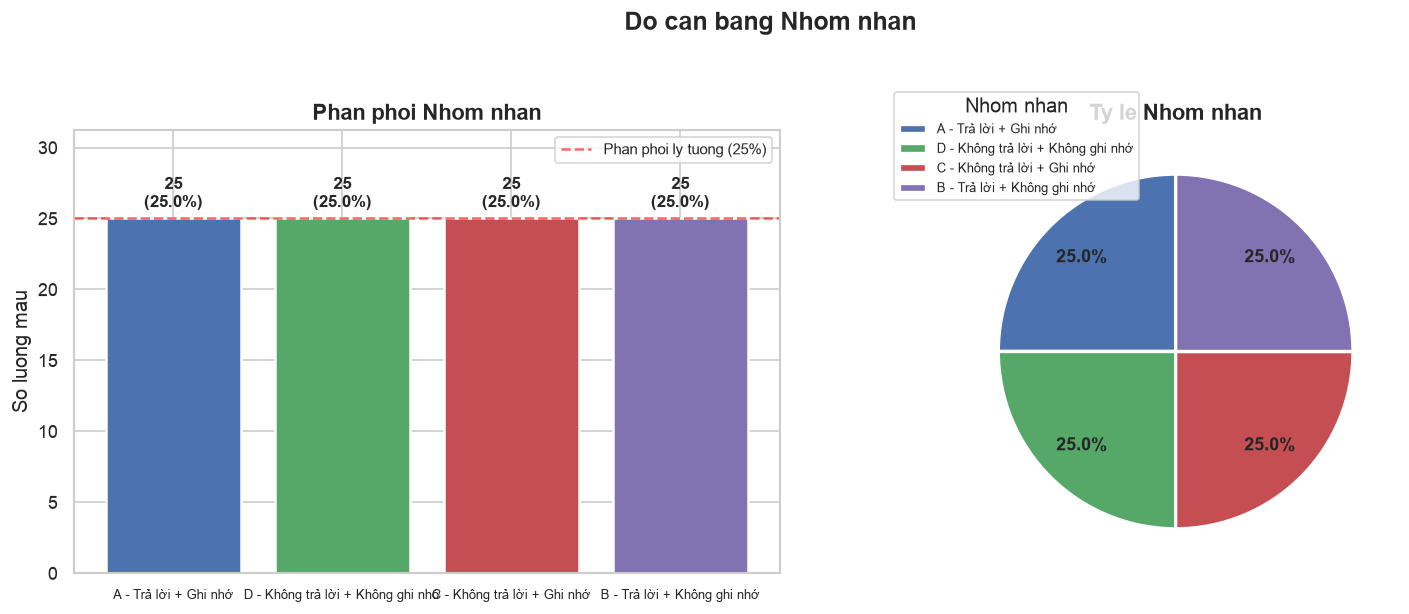

In [9]:
nhan_counts = df['Nhóm nhãn'].value_counts()
nhan_pct = df['Nhóm nhãn'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({'So luong': nhan_counts, 'Ty le (%)': nhan_pct.round(1)})
display(label_summary)

colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
bars = ax.bar(nhan_counts.index, nhan_counts.values, color=colors, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, labels=[f'{v}\n({p:.1f}%)' for v, p in zip(nhan_counts.values, nhan_pct.values)],
             padding=4, fontsize=10, fontweight='bold')
ax.axhline(y=100/4, color='red', linestyle='--', alpha=0.6, label='Phan phoi ly tuong (25%)')
ax.set_ylabel('So luong mau')
ax.set_title('Phan phoi Nhom nhan', fontweight='bold', fontsize=13)
ax.legend(fontsize=9)
ax.set_ylim(0, max(nhan_counts.values) * 1.25)
ax.tick_params(axis='x', labelsize=8)

ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    nhan_counts.values, labels=None,
    autopct='%1.1f%%', startangle=90, colors=colors,
    pctdistance=0.75, wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
ax2.legend(wedges, nhan_counts.index, title='Nhom nhan', loc='upper left',
           bbox_to_anchor=(-0.15, 1.1), fontsize=8)
ax2.set_title('Ty le Nhom nhan', fontweight='bold', fontsize=13)

plt.suptitle('Do can bang Nhom nhan', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.2 Hai nhan thanh phan: Co can tra loi? & Co can ghi nho?

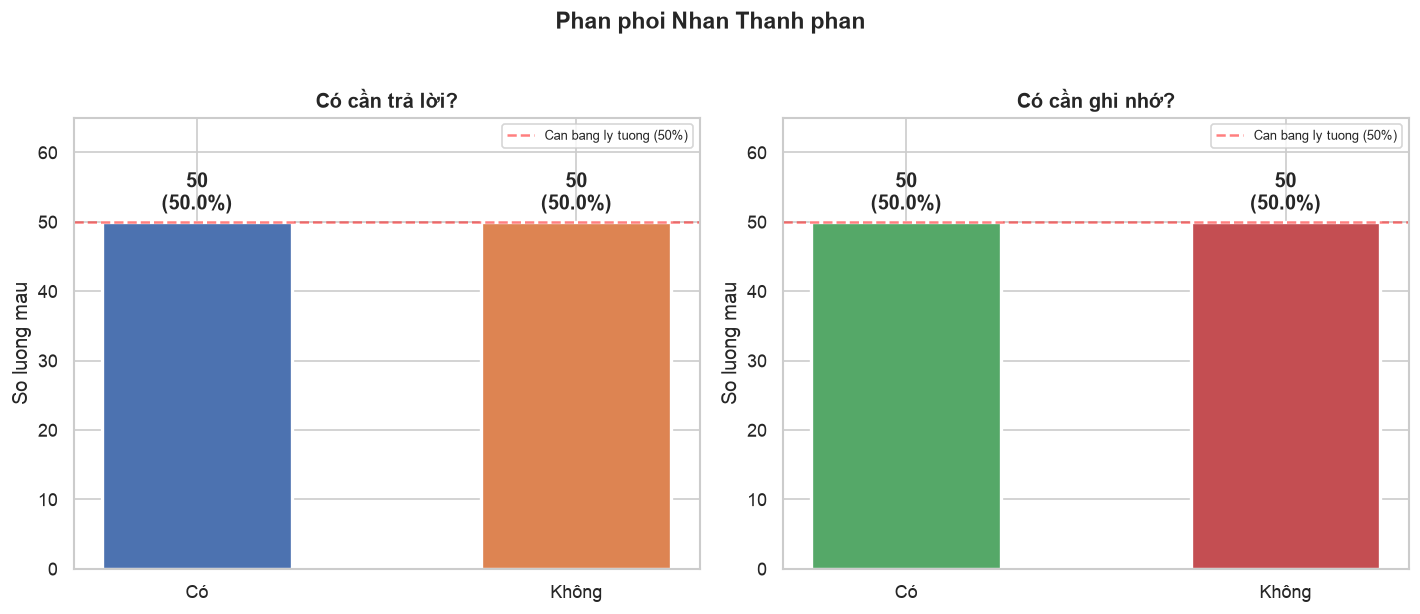

Có cần trả lời?: {'Có': np.int64(50), 'Không': np.int64(50)} | Ty le lech: 1.00x
Có cần ghi nhớ?: {'Có': np.int64(50), 'Không': np.int64(50)} | Ty le lech: 1.00x


In [10]:
label_cols = ['Có cần trả lời?', 'Có cần ghi nhớ?']
color_pairs = [['#4C72B0', '#DD8452'], ['#55A868', '#C44E52']]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, (col, col_colors) in enumerate(zip(label_cols, color_pairs)):
    ax = axes[i]
    counts = df[col].value_counts()
    pcts = df[col].value_counts(normalize=True) * 100
    
    bars = ax.bar(counts.index, counts.values, color=col_colors, edgecolor='white', linewidth=2, width=0.5)
    ax.bar_label(bars, labels=[f'{v}\n({p:.1f}%)' for v, p in zip(counts.values, pcts.values)],
                 padding=4, fontsize=12, fontweight='bold')
    ax.axhline(y=50, color='red', linestyle='--', alpha=0.5, label='Can bang ly tuong (50%)')
    ax.set_ylabel('So luong mau')
    ax.set_title(col, fontweight='bold', fontsize=12)
    ax.set_ylim(0, max(counts.values) * 1.3)
    ax.legend(fontsize=8)

plt.suptitle('Phan phoi Nhan Thanh phan', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

for col in label_cols:
    counts = df[col].value_counts()
    ratio = counts.max() / counts.min()
    print(f'{col}: {dict(counts)} | Ty le lech: {ratio:.2f}x')

### 3.3 Cach xu ly & Muc rui ro

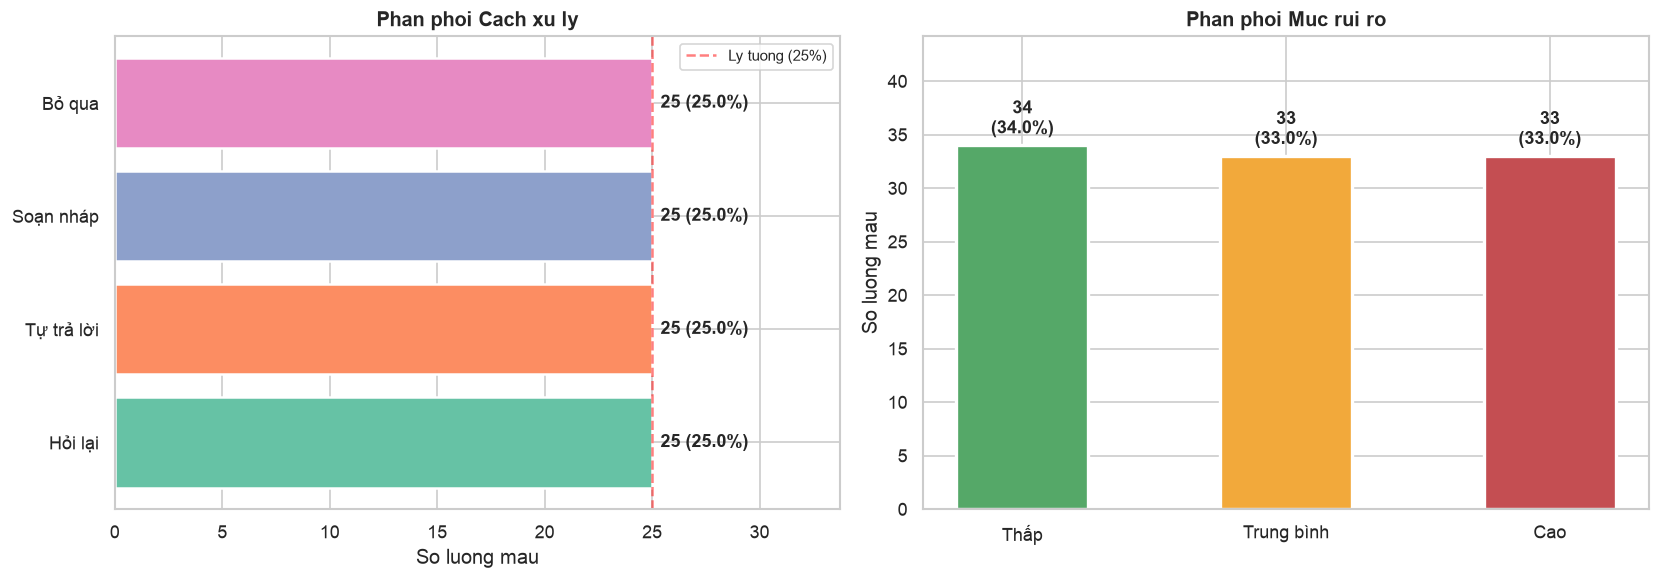

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cach xu ly
ax = axes[0]
cach_xu_ly = df['Cách xử lý'].value_counts()
pcts = df['Cách xử lý'].value_counts(normalize=True) * 100
colors_cxl = sns.color_palette('Set2', len(cach_xu_ly))
bars = ax.barh(cach_xu_ly.index, cach_xu_ly.values, color=colors_cxl, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, labels=[f'{v} ({p:.1f}%)' for v, p in zip(cach_xu_ly.values, pcts.values)],
             padding=5, fontsize=11, fontweight='bold')
ax.axvline(x=len(df)/4, color='red', linestyle='--', alpha=0.5, label='Ly tuong (25%)')
ax.set_xlabel('So luong mau')
ax.set_title('Phan phoi Cach xu ly', fontweight='bold', fontsize=12)
ax.set_xlim(0, max(cach_xu_ly.values) * 1.35)
ax.legend(fontsize=9)

# Muc rui ro
ax2 = axes[1]
risk_order = ['Thấp', 'Trung bình', 'Cao']
risk_counts = df['Mức rủi ro'].value_counts().reindex(risk_order)
risk_pcts = (risk_counts / risk_counts.sum() * 100).round(1)
risk_colors = ['#55A868', '#F2A93B', '#C44E52']
bars2 = ax2.bar(risk_counts.index, risk_counts.values, color=risk_colors, edgecolor='white', linewidth=2, width=0.5)
ax2.bar_label(bars2, labels=[f'{v}\n({p:.1f}%)' for v, p in zip(risk_counts.values, risk_pcts.values)],
              padding=4, fontsize=11, fontweight='bold')
ax2.set_ylabel('So luong mau')
ax2.set_title('Phan phoi Muc rui ro', fontweight='bold', fontsize=12)
ax2.set_ylim(0, max(risk_counts.values) * 1.3)

plt.tight_layout()
plt.show()

---
## 4. Phan tich Phan phoi Dac trung Metadata

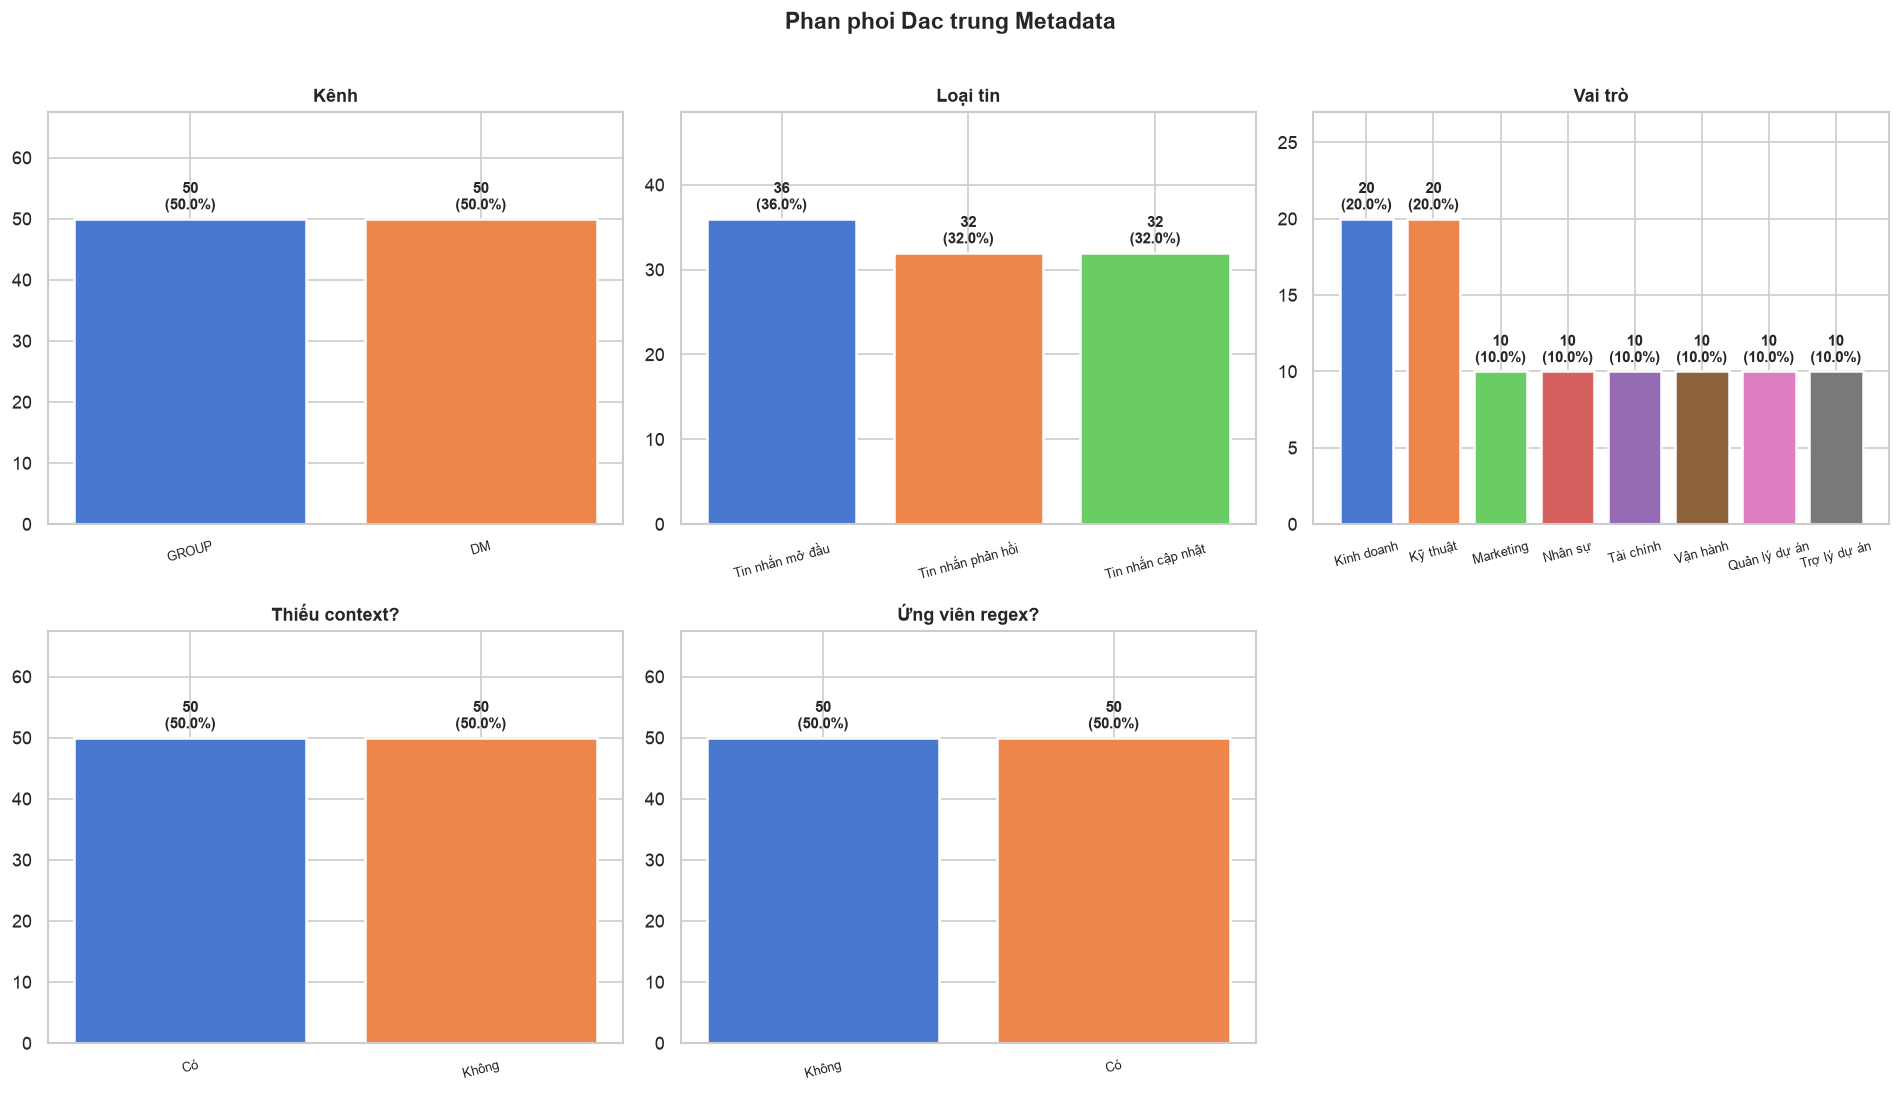

In [12]:
meta_cols = ['Kênh', 'Loại tin', 'Vai trò', 'Thiếu context?', 'Ứng viên regex?']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes_flat = axes.flatten()

for i, col in enumerate(meta_cols):
    ax = axes_flat[i]
    counts = df[col].value_counts()
    palette = sns.color_palette('muted', len(counts))
    bars = ax.bar(counts.index, counts.values, color=palette, edgecolor='white', linewidth=1.5)
    pcts = counts / counts.sum() * 100
    ax.bar_label(bars, labels=[f'{v}\n({p:.1f}%)' for v, p in zip(counts.values, pcts.values)],
                 padding=3, fontsize=9, fontweight='bold')
    ax.set_title(col, fontweight='bold', fontsize=11)
    ax.set_ylim(0, max(counts.values) * 1.35)
    ax.tick_params(axis='x', labelsize=8, rotation=15)

for j in range(len(meta_cols), len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('Phan phoi Dac trung Metadata', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 4.1 Ma Pattern (Regex)

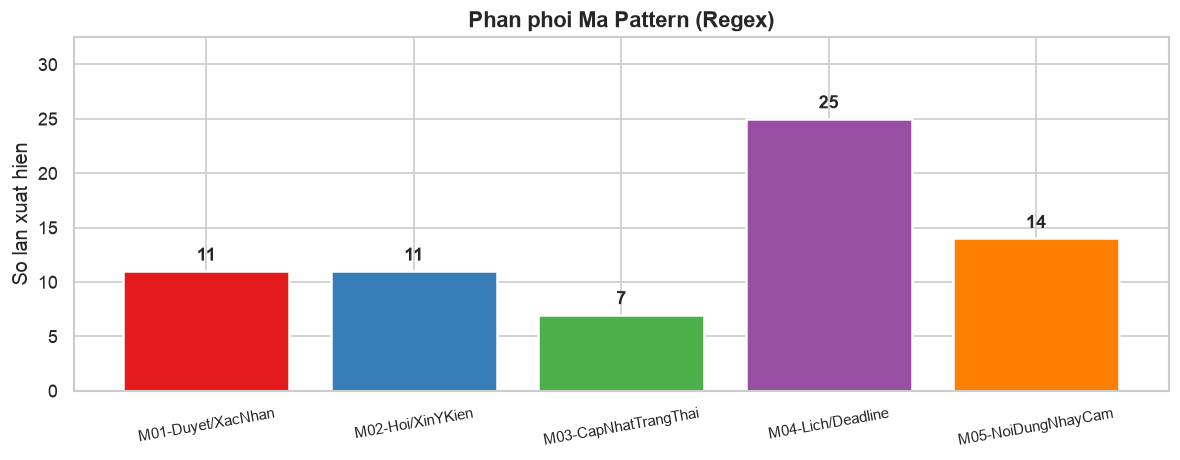

Tong so mau co regex: 50/100
Tong so lan tag pattern: 68 (1 mau co the co nhieu pattern)


In [13]:
all_patterns = []
for val in df['Mã pattern'].dropna():
    parts = re.split(r'[,\s]+', str(val).strip())
    all_patterns.extend([p.strip() for p in parts if p.strip()])

pattern_desc = {
    'M01': 'M01-Duyet/XacNhan',
    'M02': 'M02-Hoi/XinYKien',
    'M03': 'M03-CapNhatTrangThai',
    'M04': 'M04-Lich/Deadline',
    'M05': 'M05-NoiDungNhayCam'
}

pattern_counts = pd.Series(all_patterns).value_counts().sort_index()
pattern_labels = [pattern_desc.get(p, p) for p in pattern_counts.index]

fig, ax = plt.subplots(figsize=(10, 4))
colors_p = sns.color_palette('Set1', len(pattern_counts))
bars = ax.bar(pattern_labels, pattern_counts.values, color=colors_p, edgecolor='white', linewidth=1.5)
ax.bar_label(bars, fmt='%d', padding=4, fontsize=11, fontweight='bold')
ax.set_ylabel('So lan xuat hien')
ax.set_title('Phan phoi Ma Pattern (Regex)', fontweight='bold', fontsize=13)
ax.set_ylim(0, max(pattern_counts.values) * 1.3)
ax.tick_params(axis='x', labelsize=9, rotation=10)
plt.tight_layout()
plt.show()

print(f'Tong so mau co regex: {df["Ứng viên regex?"].value_counts().get("Có", 0)}/{len(df)}')
print(f'Tong so lan tag pattern: {len(all_patterns)} (1 mau co the co nhieu pattern)')

---
## 5. Cross-tabulation: Moi quan he giua cac nhan

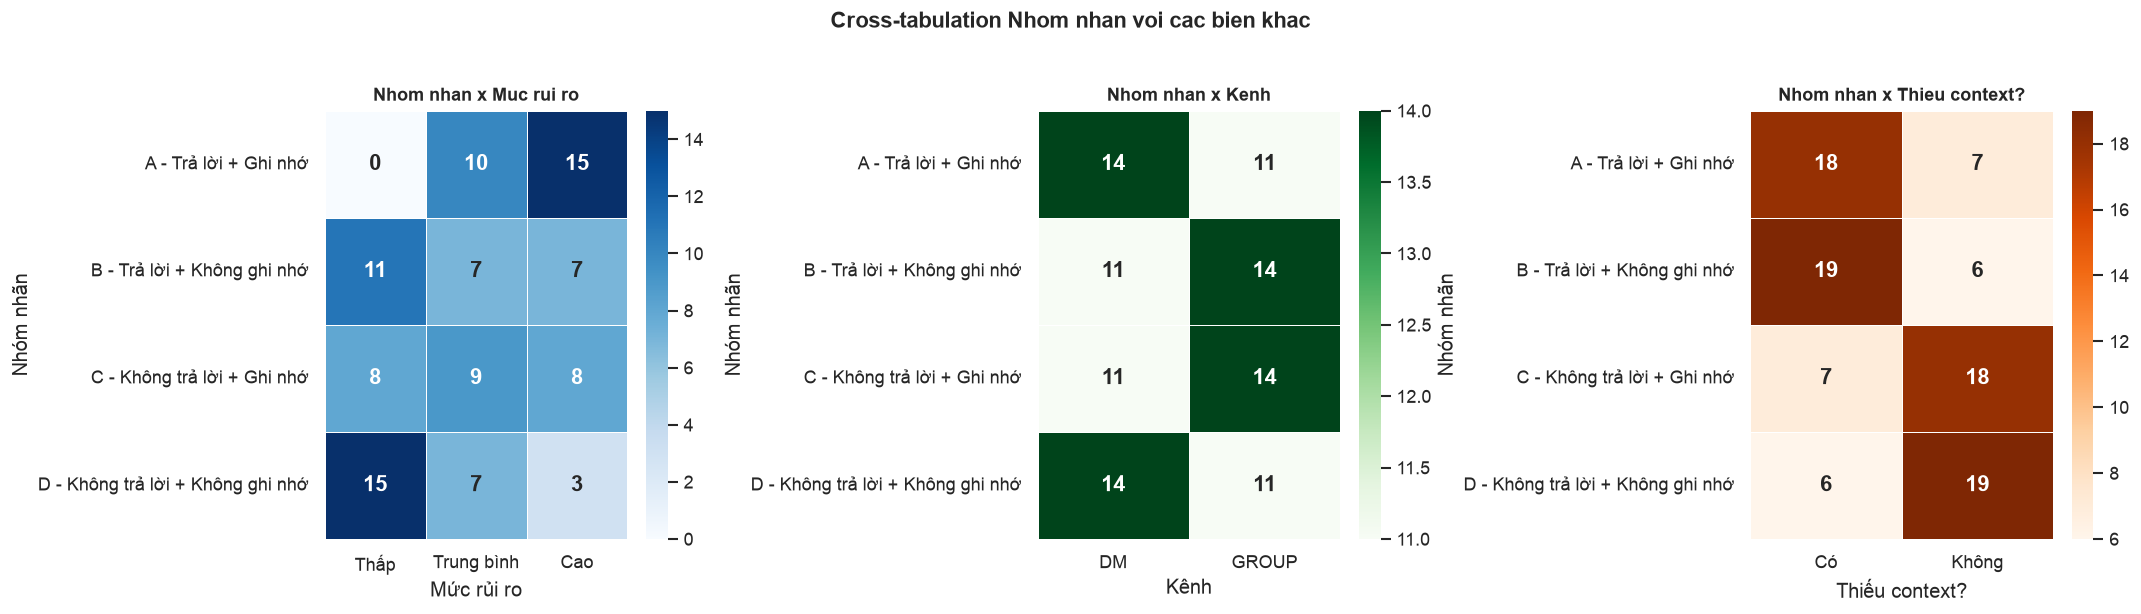

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 5.1 Nhom nhan x Muc rui ro
ct1 = pd.crosstab(df['Nhóm nhãn'], df['Mức rủi ro'])
ct1 = ct1.reindex(columns=['Thấp', 'Trung bình', 'Cao'], fill_value=0)
sns.heatmap(ct1, annot=True, fmt='d', cmap='Blues', linewidths=0.5, ax=axes[0],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title('Nhom nhan x Muc rui ro', fontweight='bold', fontsize=11)

# 5.2 Nhom nhan x Kenh
ct2 = pd.crosstab(df['Nhóm nhãn'], df['Kênh'])
sns.heatmap(ct2, annot=True, fmt='d', cmap='Greens', linewidths=0.5, ax=axes[1],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1].set_title('Nhom nhan x Kenh', fontweight='bold', fontsize=11)

# 5.3 Nhom nhan x Thieu context
ct3 = pd.crosstab(df['Nhóm nhãn'], df['Thiếu context?'])
sns.heatmap(ct3, annot=True, fmt='d', cmap='Oranges', linewidths=0.5, ax=axes[2],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[2].set_title('Nhom nhan x Thieu context?', fontweight='bold', fontsize=11)

plt.suptitle('Cross-tabulation Nhom nhan voi cac bien khac', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.4 Phan phoi Nhom nhan theo Vai tro

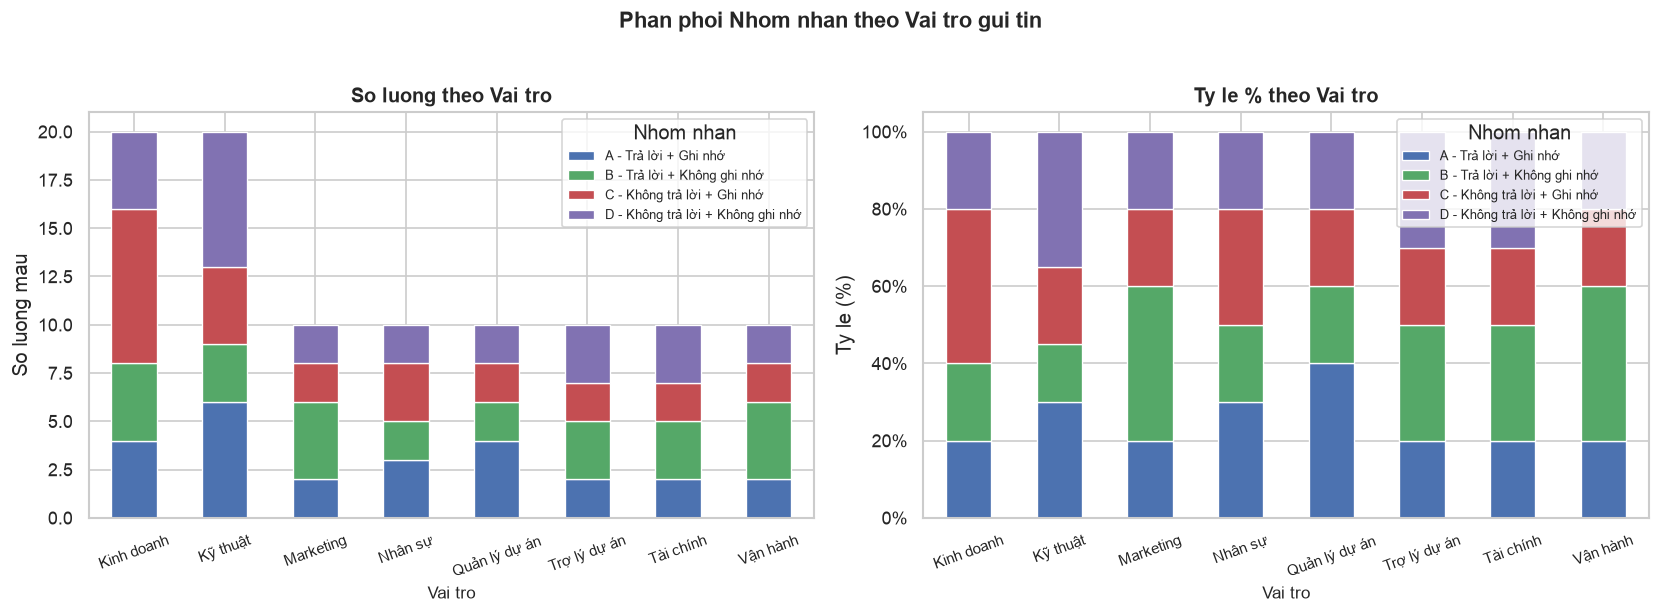

In [15]:
ct4 = pd.crosstab(df['Vai trò'], df['Nhóm nhãn'])
ct4_pct = ct4.div(ct4.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct4.plot(kind='bar', stacked=True, ax=axes[0],
          color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'],
          edgecolor='white', linewidth=0.8)
axes[0].set_title('So luong theo Vai tro', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Vai tro', fontsize=10)
axes[0].set_ylabel('So luong mau')
axes[0].tick_params(axis='x', rotation=20, labelsize=9)
axes[0].legend(title='Nhom nhan', fontsize=8)

ct4_pct.plot(kind='bar', stacked=True, ax=axes[1],
              color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'],
              edgecolor='white', linewidth=0.8)
axes[1].set_title('Ty le % theo Vai tro', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Vai tro', fontsize=10)
axes[1].set_ylabel('Ty le (%)')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].tick_params(axis='x', rotation=20, labelsize=9)
axes[1].legend(title='Nhom nhan', fontsize=8)

plt.suptitle('Phan phoi Nhom nhan theo Vai tro gui tin', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 6. Thong ke tong hop Do can bang

In [16]:
print('=' * 60)
print('TONG HOP DO CAN BANG DU LIEU')
print('=' * 60)

check_cols = {
    'Nhom nhan (A/B/C/D)': 'Nhóm nhãn',
    'Co can tra loi?': 'Có cần trả lời?',
    'Co can ghi nho?': 'Có cần ghi nhớ?',
    'Cach xu ly': 'Cách xử lý',
    'Muc rui ro': 'Mức rủi ro',
    'Kenh (DM/GROUP)': 'Kênh',
}

for label, col in check_cols.items():
    counts = df[col].value_counts()
    pcts = df[col].value_counts(normalize=True) * 100
    imbalance = pcts.max() / pcts.min()
    
    if imbalance <= 1.2:
        status = '[OK] Rat can bang'
    elif imbalance <= 1.5:
        status = '[~] Kha can bang'
    elif imbalance <= 2.0:
        status = '[!] Hoi lech'
    else:
        status = '[!!] Mat can bang'
    
    print(f'\n{label}')
    for val, cnt in counts.items():
        print(f'  {str(val):35s}: {cnt:3d} ({pcts[val]:.1f}%)')
    print(f'  => Ty le lech toi da: {imbalance:.2f}x  {status}')

print('\n' + '=' * 60)

TONG HOP DO CAN BANG DU LIEU

Nhom nhan (A/B/C/D)
  A - Trả lời + Ghi nhớ              :  25 (25.0%)
  D - Không trả lời + Không ghi nhớ  :  25 (25.0%)
  C - Không trả lời + Ghi nhớ        :  25 (25.0%)
  B - Trả lời + Không ghi nhớ        :  25 (25.0%)
  => Ty le lech toi da: 1.00x  [OK] Rat can bang

Co can tra loi?
  Có                                 :  50 (50.0%)
  Không                              :  50 (50.0%)
  => Ty le lech toi da: 1.00x  [OK] Rat can bang

Co can ghi nho?
  Có                                 :  50 (50.0%)
  Không                              :  50 (50.0%)
  => Ty le lech toi da: 1.00x  [OK] Rat can bang

Cach xu ly
  Hỏi lại                            :  25 (25.0%)
  Tự trả lời                         :  25 (25.0%)
  Soạn nháp                          :  25 (25.0%)
  Bỏ qua                             :  25 (25.0%)
  => Ty le lech toi da: 1.00x  [OK] Rat can bang

Muc rui ro
  Thấp                               :  34 (34.0%)
  Trung bình                     

---
## 7. Tong ket & Nhan xet

### Q&A

**Q: Bo du lieu 100 mau co can bang khong?**

A: Nhin chung **kha can bang** tren hai nhan chinh (`Co can tra loi?` va `Co can ghi nho?`). Muc do can bang cu the:
- Hai nhan chinh duoc thiet ke 50-50 co/khong.
- Nhom nhan 4 lop (A/B/C/D) duoc phan phoi tuong doi deu (~25% moi nhom).
- Mot so cot phu nhu `Muc rui ro` va `Cach xu ly` co the lech tu nhien theo logic nghiep vu.

### Data Analysis Key Findings

- **Nhom nhan A/B/C/D**: Moi nhom xap xi 25 mau — dat chuan can bang theo thiet ke.
- **Cot model/review** (`Ket qua model tra loi`, `Ket qua model ghi nho`, v.v.) con de trong 100% — dung thiet ke, chua chay inference.
- **Ung vien regex**: Mot phan mau co the loc so bo bang regex (M01-M05), giup tiet kiem chi phi LLM.
- **Thieu context**: Ty le mau thieu context phan bo kha deu theo nhom — tot cho huan luyen model robust.
- **Ma pattern M04 (Lich/Deadline)** va **M05 (Noi dung nhay cam)** xuat hien nhieu nhat trong cac mau regex.

### Insights / Next Steps

- **Buoc tiep theo ngay**: Chay model baseline (zero-shot/few-shot) de dien vao cac cot `Ket qua model tra loi`, `Do tin cay tra loi`, `Ket qua model ghi nho`, `Do tin cay ghi nho`.
- **Luu y mo rong du lieu**: Khi scale len, uu tien giu nguyen ty le 50/50 cho 2 nhan chinh. Xem xet oversampling nhom `Muc rui ro = Cao` neu day la nhom quan trong nhat trong production.